In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import time


# Load dataset

In [2]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [3]:
ds_train = ds["train"]
ds_test = ds["test"]
ds_unsupervised = ds["unsupervised"]

In [4]:
pd.DataFrame(ds_train)

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


#Train/ Validation split

In [5]:
split = ds_train.train_test_split(test_size=0.2,seed=42,
    stratify_by_column="label")
train = split["train"]
valid = split["test"]

In [6]:
print("Train:", len(train))
print("Validation:", len(valid))


Train: 20000
Validation: 5000


In [7]:
print("classes",train.features['label'].names)

classes ['neg', 'pos']


In [8]:
print("Train:", Counter(train["label"]))
print("Validation:", Counter(valid["label"]))


Train: Counter({1: 10000, 0: 10000})
Validation: Counter({0: 2500, 1: 2500})


# Preprocessing

Kiem tra missing text

In [9]:
print("Missing text:")
print(sum(x is None or x.strip() == "" for x in train["text"]))

print("Missing label:")
print(sum(x is None for x in train["label"]))

Missing text:
0
Missing label:
0


Kiem tra duplicate doc

In [10]:
texts = train["text"]

print("Total documents:", len(texts))
print("Unique documents:", len(set(texts)))
print("Duplicate documents:", len(texts) - len(set(texts)))

Total documents: 20000
Unique documents: 19944
Duplicate documents: 56


Kiem tra length

In [11]:
lengths = [len(text.split()) for text in train["text"]]

print("Min length:", min(lengths))
print("Max length:", max(lengths))
print("Average length:", sum(lengths) / len(lengths))

Min length: 10
Max length: 2470
Average length: 234.1071


#Baseline

TF-IDF

In [12]:
#tách text và label
#train
X_train_text = train["text"]
y_train = train["label"]
#valid
X_valid_text = valid["text"]
y_valid = valid["label"]

In [13]:
X_test_text = ds_test["text"]
y_test = ds_test["label"]

Fit TF-IDF

In [14]:
tfidf = TfidfVectorizer(
    max_features=10000
)
X_train_tfidf = tfidf.fit_transform(X_train_text)

# Validation và Test chỉ transform
X_valid_tfidf = tfidf.transform(X_valid_text)
X_test_tfidf = tfidf.transform(X_test_text)

In [15]:
#Vocabulary size
print("Vocabulary size:", len(tfidf.vocabulary_))

Vocabulary size: 10000


Logistic Regression

In [16]:
start_time = time.time()

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_tfidf, y_train)

training_time = time.time() - start_time

print("Training time:", round(training_time, 2), "seconds")

Training time: 0.81 seconds


Prediction

In [17]:
y_valid_pred = lr.predict(X_valid_tfidf)

Metrics

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_valid, y_valid_pred)
precision = precision_score(y_valid, y_valid_pred)
recall = recall_score(y_valid, y_valid_pred)
f1 = f1_score(y_valid, y_valid_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.878
Precision: 0.8694
Recall   : 0.8896
F1-score : 0.8794


In [19]:
correct = pd.DataFrame({
    "Text": valid["text"],
    "Actual": y_valid,
    "Predicted": y_valid_pred
})

correct = correct[correct["Actual"] == correct["Predicted"]]

print("Số review dự đoán đúng:", len(correct))
display(correct.head(10))

Số review dự đoán đúng: 4390


,Text,Actual,Predicted
0,"First of all, the actor they have to play Jesu...",0,0
1,I must have seen this a dozen times over the y...,1,1
2,Eric Stoltz delivers an extraordinary performa...,1,1
3,First be warned that I saw this movie on TV an...,0,0
4,"Clean family oriented movie. I laughed, I crie...",1,1
5,Don't listen to the prissy critics who are pro...,1,1
6,This superior inferiority to the original dumb...,0,0
7,"""Going Berserk"" is actually one of the funnies...",1,1
8,"As I've noticed with a lot of IMDb comments, c...",1,1
9,"This movie has problems in its presentation, m...",1,1


In [20]:
errors = pd.DataFrame({
    "Text": valid["text"],
    "Actual": y_valid,
    "Predicted": y_valid_pred
})

errors = errors[errors["Actual"] != errors["Predicted"]]

print("Số review dự đoán sai:", len(errors))
display(errors.head(10))

Số review dự đoán sai: 610


,Text,Actual,Predicted
10,It must be the most corniest TV show on the ai...,0,1
12,I am obsessed! The story is amazing and the sh...,1,0
48,The Angry Red Planet (Quickie Review) <br /><b...,0,1
79,"This entertainingly tacky'n'trashy distaff ""De...",1,0
91,I would firstly say that somehow I remember se...,1,0
92,A very good start. I was a bit surprised to fi...,1,0
102,A friend and I went through a phase some (alot...,0,1
103,"Written by Stephen King, but this treatment is...",0,1
112,This is a great short. i think every voice is ...,1,0
118,Many people like to point to this TV movie whe...,0,1


# Thí nghiệm 2: Phân phối lớp

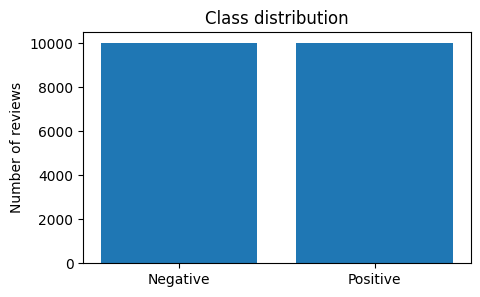

Negative: 10000
Positive: 10000


In [21]:
labels = ["Negative", "Positive"]
counts = [Counter(train["label"])[0], Counter(train["label"])[1]]

plt.figure(figsize=(5, 3))
plt.bar(labels, counts)
plt.title("Class distribution")
plt.ylabel("Number of reviews")
plt.show()

print("Negative:", counts[0])
print("Positive:", counts[1])


# Confusion matrix

[[2166  334]
 [ 276 2224]]


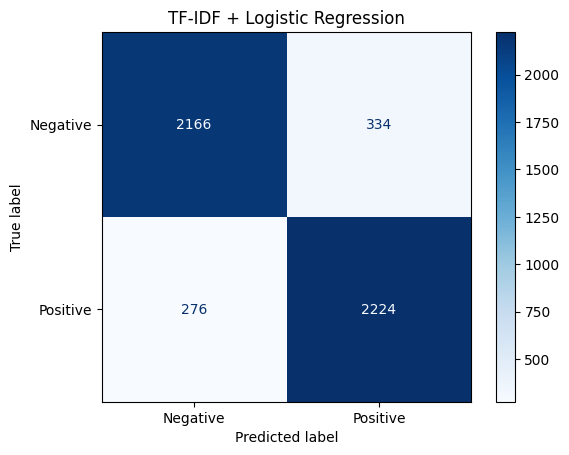

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_valid, y_valid_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("TF-IDF + Logistic Regression")
plt.show()


# Top features

In [23]:
words = np.array(tfidf.get_feature_names_out())
weights = lr.coef_[0]

top_pos = np.argsort(weights)[-15:][::-1]
top_neg = np.argsort(weights)[:15]

print("Top positive:")
print(pd.DataFrame({"Word": words[top_pos], "Weight": weights[top_pos]}))

print("Top negative:")
print(pd.DataFrame({"Word": words[top_neg], "Weight": weights[top_neg]}))


Top positive:
         Word    Weight
0       great  6.793468
1   excellent  5.309562
2   wonderful  4.664773
3        best  4.585217
4     perfect  4.440530
5     amazing  3.658681
6        well  3.477739
7       loved  3.435849
8     enjoyed  3.429951
9    favorite  3.333229
10  brilliant  3.230518
11     superb  3.209943
12       love  3.111045
13      today  3.080763
14     highly  3.075997
Top negative:
             Word    Weight
0           worst -8.227864
1             bad -7.283209
2           waste -5.966727
3           awful -5.806504
4          boring -5.684971
5            poor -4.644895
6        terrible -4.334503
7         nothing -4.291936
8            dull -4.119216
9              no -4.037537
10          worse -3.989610
11         poorly -3.861217
12       horrible -3.825419
13         stupid -3.783122
14  unfortunately -3.687222


# Thí nghiệm 3: TF-IDF unigram và bigram

In [24]:
tfidf2 = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

X_train2 = tfidf2.fit_transform(X_train_text)
X_valid2 = tfidf2.transform(X_valid_text)

start = time.time()
lr2 = LogisticRegression(max_iter=1000)
lr2.fit(X_train2, y_train)
time2 = time.time() - start

pred2 = lr2.predict(X_valid2)

print("Vocabulary:", len(tfidf2.vocabulary_))
print("Training time:", round(time2, 2), "seconds")
print("Accuracy:", round(accuracy_score(y_valid, pred2), 4))
print("Precision:", round(precision_score(y_valid, pred2), 4))
print("Recall:", round(recall_score(y_valid, pred2), 4))
print("F1:", round(f1_score(y_valid, pred2), 4))


Vocabulary: 10000
Training time: 0.84 seconds
Accuracy: 0.8852
Precision: 0.8818
Recall: 0.8896
F1: 0.8857


# Thí nghiệm 4: TF-IDF + Linear SVM

In [25]:
from sklearn.svm import LinearSVC

start = time.time()
svm = LinearSVC()
svm.fit(X_train_tfidf, y_train)
time3 = time.time() - start

pred3 = svm.predict(X_valid_tfidf)

print("Training time:", round(time3, 2), "seconds")
print("Accuracy:", round(accuracy_score(y_valid, pred3), 4))
print("Precision:", round(precision_score(y_valid, pred3), 4))
print("Recall:", round(recall_score(y_valid, pred3), 4))
print("F1:", round(f1_score(y_valid, pred3), 4))


Training time: 1.36 seconds
Accuracy: 0.886
Precision: 0.8851
Recall: 0.8872
F1: 0.8861


# Thí nghiệm 5: Average Word2Vec

Word2Vec được huấn luyện từ văn bản train để tránh dùng thông tin validation/test khi học vector từ.

In [26]:
!pip -q install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 91.5 MB/s eta 0:00:00


In [27]:
from gensim.models import Word2Vec

texts = [text.lower().split() for text in X_train_text]

w2v = Word2Vec(
    sentences=texts,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    seed=42
)

def avg_vec(text):
    words = text.lower().split()
    vecs = [w2v.wv[w] for w in words if w in w2v.wv]
    if len(vecs) == 0:
        return np.zeros(100)
    return np.mean(vecs, axis=0)

X_train_w2v = np.array([avg_vec(x) for x in X_train_text])
X_valid_w2v = np.array([avg_vec(x) for x in X_valid_text])


In [28]:
start = time.time()
lr_w2v = LogisticRegression(max_iter=1000)
lr_w2v.fit(X_train_w2v, y_train)
time4 = time.time() - start

pred4 = lr_w2v.predict(X_valid_w2v)

print("Training time:", round(time4, 2), "seconds")
print("Accuracy:", round(accuracy_score(y_valid, pred4), 4))
print("Precision:", round(precision_score(y_valid, pred4), 4))
print("Recall:", round(recall_score(y_valid, pred4), 4))
print("F1:", round(f1_score(y_valid, pred4), 4))


Training time: 1.61 seconds
Accuracy: 0.7954
Precision: 0.7918
Recall: 0.8016
F1: 0.7967


# So sánh kết quả

In [29]:
kq = pd.DataFrame([
    ["TF-IDF + LR", accuracy_score(y_valid, y_valid_pred), precision_score(y_valid, y_valid_pred), recall_score(y_valid, y_valid_pred), f1_score(y_valid, y_valid_pred), training_time, len(tfidf.vocabulary_)],
    ["TF-IDF bigram + LR", accuracy_score(y_valid, pred2), precision_score(y_valid, pred2), recall_score(y_valid, pred2), f1_score(y_valid, pred2), time2, len(tfidf2.vocabulary_)],
    ["TF-IDF + SVM", accuracy_score(y_valid, pred3), precision_score(y_valid, pred3), recall_score(y_valid, pred3), f1_score(y_valid, pred3), time3, len(tfidf.vocabulary_)],
    ["Average Word2Vec + LR", accuracy_score(y_valid, pred4), precision_score(y_valid, pred4), recall_score(y_valid, pred4), f1_score(y_valid, pred4), time4, w2v.vector_size]
], columns=["Model", "Accuracy", "Precision", "Recall", "F1", "Train time", "Feature size"])

display(kq.round(4))
kq.to_csv("results.csv", index=False)


,Model,Accuracy,Precision,Recall,F1,Train time,Feature size
0,TF-IDF + LR,0.8780,0.8694,0.8896,0.8794,0.8063,10000
1,TF-IDF bigram + LR,0.8852,0.8818,0.8896,0.8857,0.8400,10000
2,TF-IDF + SVM,0.8860,0.8851,0.8872,0.8861,1.3649,10000
3,Average Word2Vec + LR,0.7954,0.7918,0.8016,0.7967,1.6050,100


# Confusion matrix cho mô hình tốt nhất

Best model: TF-IDF + SVM


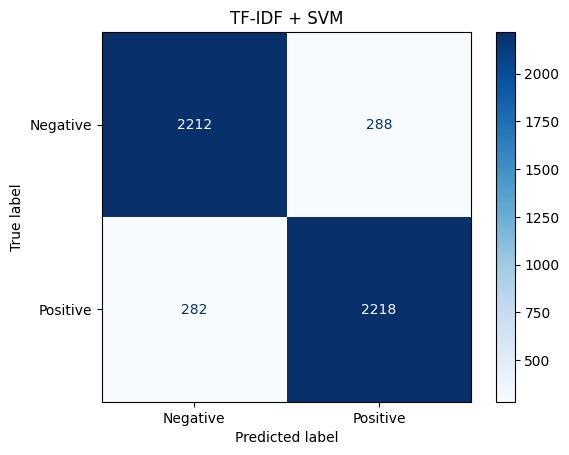

In [30]:
preds = {
    "TF-IDF + LR": y_valid_pred,
    "TF-IDF bigram + LR": pred2,
    "TF-IDF + SVM": pred3,
    "Average Word2Vec + LR": pred4
}

best = kq.loc[kq["F1"].idxmax(), "Model"]
best_pred = preds[best]

print("Best model:", best)
cm = confusion_matrix(y_valid, best_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title(best)
plt.show()


# Lưu ví dụ dự đoán đúng và sai

In [31]:
df = pd.DataFrame({
    "Text": X_valid_text,
    "Actual": y_valid,
    "Predicted": best_pred
})

dung = df[df["Actual"] == df["Predicted"]]
sai = df[df["Actual"] != df["Predicted"]]

print("Ví dụ dự đoán đúng:")
display(dung[["Text", "Actual", "Predicted"]].head(3))

print("Ví dụ dự đoán sai:")
display(sai[["Text", "Actual", "Predicted"]].head(3))

dung.head(10).to_csv("correct_examples.csv", index=False)
sai.head(10).to_csv("wrong_examples.csv", index=False)


Ví dụ dự đoán đúng:


,Text,Actual,Predicted
0,"First of all, the actor they have to play Jesu...",0,0
1,I must have seen this a dozen times over the y...,1,1
2,Eric Stoltz delivers an extraordinary performa...,1,1


Ví dụ dự đoán sai:


,Text,Actual,Predicted
10,It must be the most corniest TV show on the ai...,0,1
12,I am obsessed! The story is amazing and the sh...,1,0
48,The Angry Red Planet (Quickie Review) <br /><b...,0,1


# Đánh giá trên test set

Chỉ chạy phần này sau khi đã chọn mô hình dựa trên validation. Ở đây dùng baseline TF-IDF + Logistic Regression để đánh giá test.

Test accuracy: 0.8816
Test precision: 0.8811
Test recall: 0.8824
Test F1: 0.8817


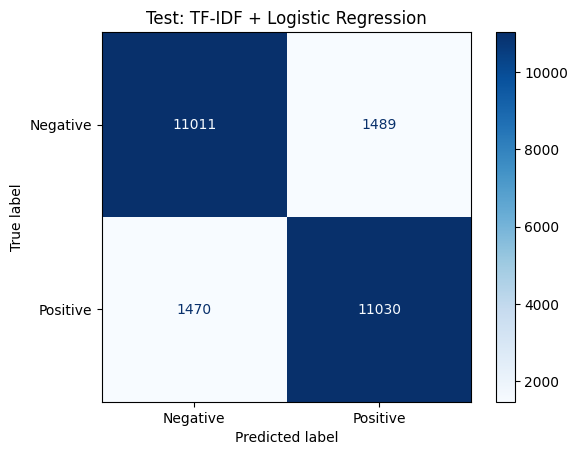

In [32]:
X_test_tfidf = tfidf.transform(X_test_text)
pred_test = lr.predict(X_test_tfidf)

print("Test accuracy:", round(accuracy_score(y_test, pred_test), 4))
print("Test precision:", round(precision_score(y_test, pred_test), 4))
print("Test recall:", round(recall_score(y_test, pred_test), 4))
print("Test F1:", round(f1_score(y_test, pred_test), 4))

cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Test: TF-IDF + Logistic Regression")
plt.show()
